# ML2 — Truncated SVD: choosing the number of components k

**Project:** DS 5020 Mini-Project "Customers Like You".

Input: the frozen `data/processed/A_log.npz` (5,471 customers × 3,687 products, read-only). Model: scikit-learn
`TruncatedSVD(algorithm="randomized", n_iter=7, random_state=42)`, per the ML1 decision note.

For each \(k \in \{10, 20, 50, 100, 200\}\) we record fit time, relative reconstruction error, energy kept and
stored factor size. \(A_k\) is **never** reconstructed densely for the real matrix: the error comes from the singular
values alone,

\[
\|A - A_k\|_F^2 = \|A\|_F^2 - \sum_{i \le k} \sigma_i^2
\qquad\Rightarrow\qquad
\text{rel\_error}(k) = \sqrt{1 - \frac{\sum_{i \le k} \sigma_i^2}{\|A\|_F^2}} .
\]

**This notebook does not choose k.** It prints the table and stops.

In [1]:
# Environment guard: this notebook must run in the "giftlane" conda env (pandas 3.0.6).
# It fails fast with "Wrong Python environment. Run: conda activate giftlane" otherwise.
import sys
from pathlib import Path

_ROOT = Path.cwd().resolve()
if _ROOT.name == "notebooks":
    _ROOT = _ROOT.parent
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from src.env_check import check_env

print("environment OK:", check_env())

environment OK: /opt/homebrew/Caskroom/miniforge/base/envs/giftlane/bin/python3.11


## 0. Setup and load the frozen matrix

In [2]:
import time

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from src.svd import (
    K_GRID, N_ITER, SEED,
    error_curve, factor_size_mb, load_inputs, projection_rel_error, rel_error,
    sweep_k, top_products_for_component, total_energy, validate_error_formula,
)

ROOT = _ROOT
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

A, product_index, customer_index = load_inputs(ROOT)
n_customers, n_products = A.shape
print("python  :", sys.executable)
print("sklearn :", sklearn.__version__, "| numpy :", np.__version__, "| pandas :", pd.__version__)
print(f"A_log   : {n_customers:,} x {n_products:,}, nnz {A.nnz:,}, sparsity {100 * (1 - A.nnz / (n_customers * n_products)):.2f}%")
print(f"dense   : {n_customers * n_products * 8 / 1e6:.1f} MB")

python  : /opt/homebrew/Caskroom/miniforge/base/envs/giftlane/bin/python
sklearn : 1.9.1 | numpy : 2.4.6 | pandas : 3.0.6
A_log   : 5,471 x 3,687, nnz 413,706, sparsity 97.95%
dense   : 161.4 MB


## 1. Total energy \(\|A\|_F^2\)

Sum of squared stored values. With `log1p` values this is the quantity every \(\sigma_i^2\) is measured against.

In [3]:
energy = total_energy(A)
print(f"||A||_F^2 = sum(A.data**2) = {energy:,.4f}")
print(f"||A||_F   = {np.sqrt(energy):,.4f}")
print(f"mean squared non-zero value = {energy / A.nnz:.4f}")

||A||_F^2 = sum(A.data**2) = 2,389,340.1285
||A||_F   = 1,545.7491
mean squared non-zero value = 5.7755


## 2. Validate the error formula on small matrices

- **Random 200×200 sparse matrix** (density 0.05, seed 42), k = 20: the formula is compared with an explicit dense
  reconstruction \(\|A - U_k \Sigma_k V_k^\top\|_F / \|A\|_F\) from `np.linalg.svd`. Asserted to agree to 1e-6.
  The same comparison with sklearn's *randomized* `TruncatedSVD` is also reported: its \(U\Sigma\) comes from a random
  sketch, so on a flat-spectrum random matrix the two numbers differ by the sketch gap (~1e-4). That is a property of
  the randomized solver, not of the formula.
- **\([[3,0],[4,5]]\)** with full `np.linalg.svd`: singular values must be \(3\sqrt5\) and \(\sqrt5\), and the k = 1
  relative error must be \(\sqrt{0.1}\).

In [4]:
v = validate_error_formula(seed=SEED, tol=1e-6)

r = v["random_200x200"]
print(f"random 200x200 (nnz {r['nnz']}), k={r['k']}")
e = r["exact_svd"]
print(f"  exact SVD      : formula {e['rel_error_formula']:.10f} | explicit {e['rel_error_explicit']:.10f} | |diff| {e['abs_diff']:.2e}  -> PASS (< 1e-6)")
t = r["randomized_truncated_svd"]
print(f"  TruncatedSVD   : formula {t['rel_error_formula']:.10f} | explicit {t['rel_error_explicit']:.10f} | |diff| {t['abs_diff']:.2e}  (sketch gap; max |sigma - sigma_exact| = {t['max_abs_gap_in_singular_values_vs_exact']:.2e})")

m = v["matrix_2x2"]
print()
print("[[3,0],[4,5]]")
print(f"  singular values : {m['singular_values']}  expected (3*sqrt5, sqrt5) = {m['expected']}  -> PASS")
print(f"  ||A||_F^2       : {m['frobenius_sq']}")
print(f"  k=1 rel error   : formula {m['k1_rel_error_formula']:.12f} | explicit {m['k1_rel_error_explicit']:.12f} | sqrt(0.1) = {m['expected_k1_rel_error']:.12f}  -> PASS")

random 200x200 (nnz 2000), k=20
  exact SVD      : formula 0.8011586747 | explicit 0.8011586747 | |diff| 2.22e-16  -> PASS (< 1e-6)
  TruncatedSVD   : formula 0.8015631619 | explicit 0.8014790004 | |diff| 8.42e-05  (sketch gap; max |sigma - sigma_exact| = 1.53e-02)

[[3,0],[4,5]]
  singular values : [6.70820393249937, 2.2360679774997894]  expected (3*sqrt5, sqrt5) = [6.708203932499369, 2.23606797749979]  -> PASS
  ||A||_F^2       : 50.0
  k=1 rel error   : formula 0.316227766017 | explicit 0.316227766017 | sqrt(0.1) = 0.316227766017  -> PASS


## 3. Sweep k ∈ {10, 20, 50, 100, 200}

One `TruncatedSVD` fit per k. Factor size assumes float64 storage of \(U_k\) (n×k) and \(V_k\) (m×k):
\((n + m)\,k \cdot 8 / 10^6\) MB.

In [5]:
results, models = sweep_k(A, ks=K_GRID, seed=SEED, n_iter=N_ITER, verbose=True)

k=  10: fit   0.04s | rel_error 0.8759 | energy kept  23.28% | factors 0.73 MB


k=  20: fit   0.06s | rel_error 0.8457 | energy kept  28.49% | factors 1.47 MB


k=  50: fit   0.10s | rel_error 0.7892 | energy kept  37.71% | factors 3.66 MB


k= 100: fit   0.19s | rel_error 0.7270 | energy kept  47.15% | factors 7.33 MB


k= 200: fit   0.37s | rel_error 0.6383 | energy kept  59.25% | factors 14.65 MB


### Cross-check on the real matrix (no dense reconstruction)

The model's own reconstruction is \(A_k = A V_k^\top V_k\). Since the rows of \(V_k\) are orthonormal,
\(\|A - A_k\|_F^2 = \|A\|_F^2 - \|A V_k^\top\|_F^2\), and \(A V_k^\top\) is only n×k. This gives the exact
error of the fitted model with one sparse matmul, to compare with the singular-value formula.

In [6]:
chk = pd.DataFrame(
    {
        "k": list(models),
        "rel_error_formula": [rel_error(models[k].singular_values_, energy) for k in models],
        "rel_error_projection_exact": [projection_rel_error(A, models[k], energy) for k in models],
    }
)
chk["abs_diff"] = (chk["rel_error_formula"] - chk["rel_error_projection_exact"]).abs()
print(chk.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
assert (chk["abs_diff"] < 1e-3).all()
print("\nformula and exact projection error agree to < 1e-3 at every k (difference = randomized-sketch gap)")

  k  rel_error_formula  rel_error_projection_exact  abs_diff
 10           0.875911                    0.875910  0.000001
 20           0.845661                    0.845653  0.000008
 50           0.789225                    0.789174  0.000051
100           0.726999                    0.726900  0.000098
200           0.638347                    0.638210  0.000138

formula and exact projection error agree to < 1e-3 at every k (difference = randomized-sketch gap)


## 4. Figures

- **Scree plot:** singular values 1..200 from the single k = 200 fit (linear and log scale).
- **Error / energy vs k:** curves from the cumulative singular values of the k = 200 fit, with the five sweep fits
  marked as points.

No customer IDs appear anywhere.

In [7]:
svd200 = models[200]
sv = svd200.singular_values_
curve = error_curve(sv, energy)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, log in zip(axes, (False, True)):
    ax.plot(np.arange(1, len(sv) + 1), sv, marker="o", markersize=2.5, linewidth=1)
    ax.set_xlabel("component index i")
    ax.set_ylabel("singular value  σ_i" + ("  (log scale)" if log else ""))
    ax.set_title("Scree plot of A_log (TruncatedSVD, k = 200)" + (" — log scale" if log else ""))
    if log:
        ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
    for k in K_GRID:
        ax.axvline(k, color="grey", linestyle=":", linewidth=0.8)
fig.tight_layout()
scree_path = FIG_DIR / "ml2_scree.png"
fig.savefig(scree_path, dpi=150)
plt.close(fig)

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(curve["k"], curve["rel_error"], color="tab:red", label="relative reconstruction error")
ax1.scatter(results["k"], results["rel_error"], color="tab:red", zorder=3)
ax1.set_xlabel("number of components k")
ax1.set_ylabel("relative error  ||A − A_k||_F / ||A||_F", color="tab:red")
ax1.tick_params(axis="y", labelcolor="tab:red")
ax1.set_ylim(0, 1)
ax2 = ax1.twinx()
ax2.plot(curve["k"], curve["energy_kept_pct"], color="tab:blue", label="energy kept (%)")
ax2.scatter(results["k"], results["energy_kept_pct"], color="tab:blue", zorder=3)
ax2.set_ylabel("energy kept  Σσ_i² / ||A||_F²  (%)", color="tab:blue")
ax2.tick_params(axis="y", labelcolor="tab:blue")
ax2.set_ylim(0, 100)
offsets = {10: (-10, -28), 20: (8, 6), 50: (8, 6), 100: (8, 6), 200: (-44, 8)}
for _, r in results.iterrows():
    k = int(r.k)
    ax1.annotate(f"k={k}\n{r.rel_error:.3f}", (r.k, r.rel_error), textcoords="offset points", xytext=offsets[k], fontsize=8, color="tab:red")
    ax2.annotate(f"{r.energy_kept_pct:.1f}%", (r.k, r.energy_kept_pct), textcoords="offset points", xytext=(6, -14), fontsize=8, color="tab:blue")
ax1.set_xlim(-8, 215)
ax1.set_title("Reconstruction error and energy kept vs k (A_log)")
ax1.grid(True, alpha=0.3)
fig.tight_layout()
err_path = FIG_DIR / "ml2_error_vs_k.png"
fig.savefig(err_path, dpi=150)
plt.close(fig)

print("saved ->", scree_path.relative_to(ROOT))
print("saved ->", err_path.relative_to(ROOT))

saved -> reports/figures/ml2_scree.png
saved -> reports/figures/ml2_error_vs_k.png


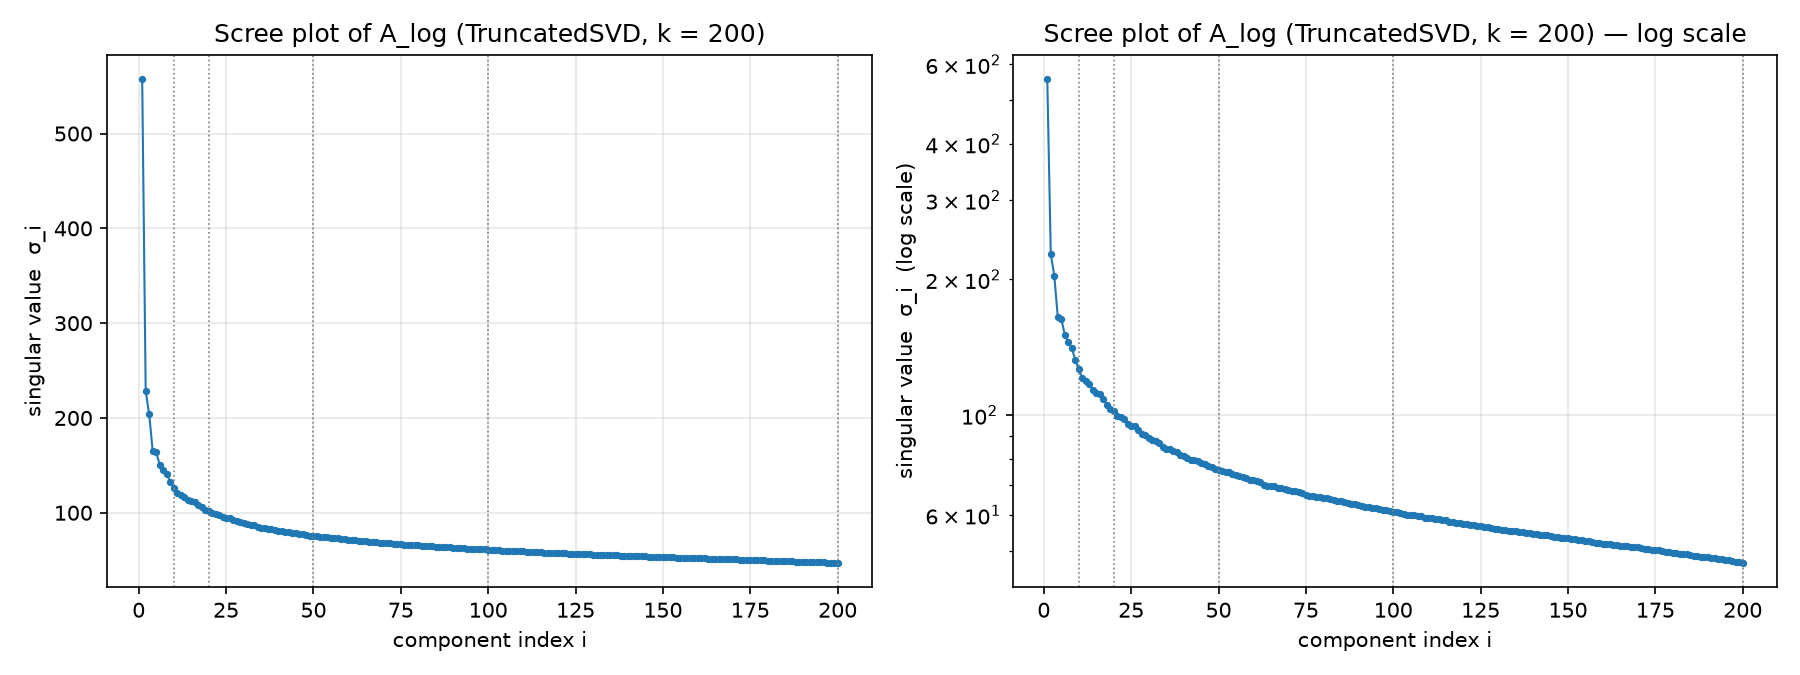

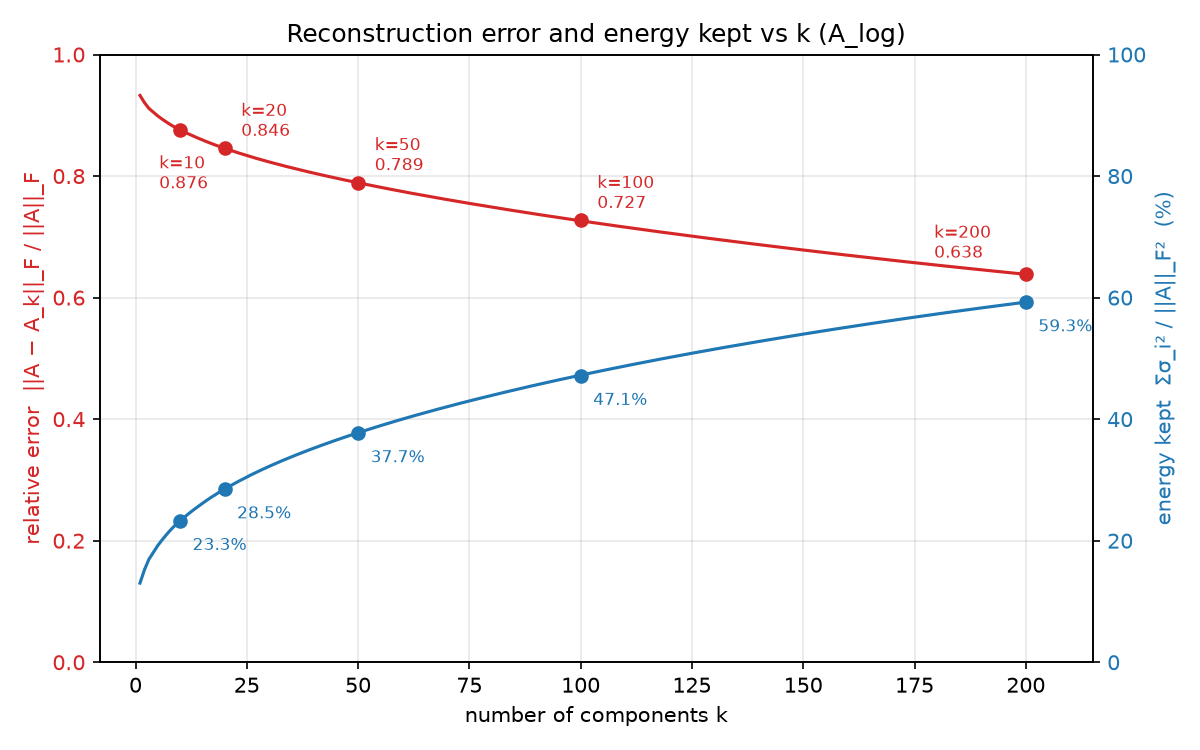

In [8]:
from IPython.display import Image, display
display(Image(filename=str(scree_path)))
display(Image(filename=str(err_path)))

## 5. Results table

Saved to `reports/ml2_k_results.csv`.

In [9]:
table = results[["k", "fit_s", "rel_error", "energy_kept_pct", "factors_MB"]].copy()
with pd.option_context("display.float_format", lambda x: f"{x:,.4f}"):
    print(table.to_string(index=False))
out_csv = ROOT / "reports" / "ml2_k_results.csv"
table.to_csv(out_csv, index=False)
print("\nsaved ->", out_csv.relative_to(ROOT))
print(f"\nfor reference: dense A_log = {n_customers * n_products * 8 / 1e6:.1f} MB; "
      f"J1 target is factors < 5 MB and nightly fit + score < 60 s")

  k  fit_s  rel_error  energy_kept_pct  factors_MB
 10 0.0370     0.8759          23.2781      0.7326
 20 0.0570     0.8457          28.4857      1.4653
 50 0.1010     0.7892          37.7124      3.6632
100 0.1910     0.7270          47.1473      7.3264
200 0.3710     0.6383          59.2513     14.6528

saved -> reports/ml2_k_results.csv

for reference: dense A_log = 161.4 MB; J1 target is factors < 5 MB and nightly fit + score < 60 s


## 6. What do the leading components mean?

First 10 singular values, then the top 10 products by absolute weight in component 1 and component 2 (from the
k = 200 fit; leading components are stable across k). Descriptions come from `product_index.parquet`.

In [10]:
print("first 10 singular values:")
for i, s in enumerate(sv[:10], start=1):
    print(f"  σ_{i:<2d} = {s:10.4f}   (σ_i² / ||A||_F² = {100 * s**2 / energy:5.2f}%)")

for c in (0, 1):
    print(f"\ncomponent {c + 1}: top 10 products by |weight|")
    print(top_products_for_component(svd200, product_index, c, n=10).to_string())

first 10 singular values:
  σ_1  =   557.8367   (σ_i² / ||A||_F² = 13.02%)
  σ_2  =   227.9592   (σ_i² / ||A||_F² =  2.17%)
  σ_3  =   203.9750   (σ_i² / ||A||_F² =  1.74%)
  σ_4  =   165.2696   (σ_i² / ||A||_F² =  1.14%)
  σ_5  =   163.8449   (σ_i² / ||A||_F² =  1.12%)
  σ_6  =   150.8331   (σ_i² / ||A||_F² =  0.95%)
  σ_7  =   145.3103   (σ_i² / ||A||_F² =  0.88%)
  σ_8  =   140.8122   (σ_i² / ||A||_F² =  0.83%)
  σ_9  =   132.8654   (σ_i² / ||A||_F² =  0.74%)
  σ_10 =   126.2690   (σ_i² / ||A||_F² =  0.67%)

component 1: top 10 products by |weight|
     StockCode                         Description    weight  n_customers_train
rank                                                                           
1        21212    PACK OF 72 RETRO SPOT CAKE CASES  0.129860               1058
2       85123A  WHITE HANGING HEART T-LIGHT HOLDER  0.121932               1422
3       85099B             JUMBO BAG RED RETROSPOT  0.108465                898
4        20725             LUNCH BAG RED R

## Stop here

k is **not** chosen in this notebook. The table above (`reports/ml2_k_results.csv`), the two figures, and the
component read-outs are the inputs to that decision, which is recorded in `decision_log.md` separately.